Task 3: Cuisine Classification

2. Load and Inspect the Dataset

In [2]:
import pandas as pd
import numpy as np
from IPython.display import display

# Load the dataset from the same folder as this notebook
df = pd.read_csv("Dataset .csv")

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values by column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate rows:", df.duplicated().sum())

display(df.head())

Dataset loaded successfully.
Dataset shape: (9551, 21)

Column names:
['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address', 'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines', 'Average Cost for two', 'Currency', 'Has Table booking', 'Has Online delivery', 'Is delivering now', 'Switch to order menu', 'Price range', 'Aggregate rating', 'Rating color', 'Rating text', 'Votes']

Missing values by column:


,Missing Values
Restaurant ID,0
Restaurant Name,0
Country Code,0
City,0
Address,0
Locality,0
Locality Verbose,0
Longitude,0
Latitude,0
Cuisines,9



Duplicate rows: 0


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


3. Prepare the Target and Features

In [3]:
# Keep the columns that can reasonably help describe a restaurant
feature_columns = [
    "Country Code",
    "City",
    "Longitude",
    "Latitude",
    "Average Cost for two",
    "Currency",
    "Has Table booking",
    "Has Online delivery",
    "Is delivering now",
    "Switch to order menu",
    "Price range",
    "Aggregate rating",
    "Votes"
]

required_columns = ["Cuisines"] + feature_columns
missing_columns = [col for col in required_columns if col not in df.columns]

if missing_columns:
    raise KeyError(f"These expected columns are missing from the dataset: {missing_columns}")

data = df[required_columns].copy()

# Remove rows where a cuisine label is unavailable
data = data.dropna(subset=["Cuisines"]).copy()

# Use the first cuisine listed as the primary cuisine label
data["Primary Cuisine"] = (
    data["Cuisines"]
    .astype(str)
    .str.split(",")
    .str[0]
    .str.strip()
)

# Remove empty target labels, if any
data = data[data["Primary Cuisine"].ne("")].copy()

# The original multi-cuisine text is not used as an input feature
X = data[feature_columns].copy()
y = data["Primary Cuisine"].copy()

print("Rows available after preparing cuisine labels:", len(data))
print("Number of primary-cuisine classes before rare-class handling:", y.nunique())

print("\nMost common primary cuisines:")
display(y.value_counts().head(15).to_frame("Restaurant Count"))

Rows available after preparing cuisine labels: 9542
Number of primary-cuisine classes before rare-class handling: 119

Most common primary cuisines:


,Restaurant Count
Primary Cuisine,
North Indian,2992
Chinese,855
Fast Food,672
Bakery,621
Cafe,617
American,278
South Indian,262
Mithai,246
Street Food,236


4. Handle Missing Values

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

print("\nMissing values in numerical features:")
display(X[numeric_features].isnull().sum().to_frame("Missing Values"))

print("\nMissing values in categorical features:")
display(X[categorical_features].isnull().sum().to_frame("Missing Values"))

Numerical features: ['Country Code', 'Longitude', 'Latitude', 'Average Cost for two', 'Price range', 'Aggregate rating', 'Votes']
Categorical features: ['City', 'Currency', 'Has Table booking', 'Has Online delivery', 'Is delivering now', 'Switch to order menu']

Missing values in numerical features:


,Missing Values
Country Code,0
Longitude,0
Latitude,0
Average Cost for two,0
Price range,0
Aggregate rating,0
Votes,0



Missing values in categorical features:


,Missing Values
City,0
Currency,0
Has Table booking,0
Has Online delivery,0
Is delivering now,0
Switch to order menu,0


5. Prepare Classes for Training

In [5]:
minimum_class_count = 20

class_counts = y.value_counts()
eligible_classes = class_counts[class_counts >= minimum_class_count].index

model_data = data[data["Primary Cuisine"].isin(eligible_classes)].copy()
X_model = model_data[feature_columns].copy()
y_model = model_data["Primary Cuisine"].copy()

print("Minimum records per cuisine class:", minimum_class_count)
print("Rows retained for modelling:", len(model_data))
print("Cuisine classes retained:", y_model.nunique())
print("Rows excluded because their cuisine class was rare:", len(data) - len(model_data))

print("\nClass distribution used for modelling:")
display(y_model.value_counts().to_frame("Restaurant Count"))

Minimum records per cuisine class: 20
Rows retained for modelling: 9097
Cuisine classes retained: 33
Rows excluded because their cuisine class was rare: 445

Class distribution used for modelling:


,Restaurant Count
Primary Cuisine,
North Indian,2992
Chinese,855
Fast Food,672
Bakery,621
Cafe,617
American,278
South Indian,262
Mithai,246
Street Food,236


6. Split the Data into Training and Testing Sets

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X_model,
    y_model,
    test_size=0.20,
    random_state=42,
    stratify=y_model
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training feature shape: (7277, 13)
Testing feature shape: (1820, 13)
Training target shape: (7277,)
Testing target shape: (1820,)


7. Encode Categorical Variables and Train the Classifier

In [7]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

classifier = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", classifier)
])

model.fit(X_train, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


8. Evaluate the Model

In [8]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
macro_precision = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)
macro_recall = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)

print(f"Accuracy: {accuracy:.4f}")
print(f"Macro Precision: {macro_precision:.4f}")
print(f"Macro Recall: {macro_recall:.4f}")

print("\nClassification report by cuisine:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.0725
Macro Precision: 0.1065
Macro Recall: 0.1833

Classification report by cuisine:
               precision    recall  f1-score   support

     American       0.17      0.04      0.06        56
        Asian       0.00      0.00      0.00        15
       Bakery       0.13      0.04      0.06       124
    Beverages       0.02      0.25      0.04        16
      Biryani       0.02      0.05      0.03        22
    Brazilian       0.44      1.00      0.62         4
    Breakfast       0.12      0.40      0.18         5
       Burger       0.14      0.13      0.14        23
         Cafe       0.21      0.11      0.15       124
      Chinese       0.17      0.01      0.02       171
  Continental       0.08      0.06      0.07        47
     Desserts       0.07      0.03      0.05        30
     European       0.06      0.17      0.09        12
    Fast Food       0.00      0.00      0.00       135
  Finger Food       0.13      0.75      0.22        16
 Healthy Food       0.

9. Analyze Performance Across Cuisines

,precision,recall,f1-score,support
Tibetan,0.000000,0.000000,0.000000,4.0
Asian,0.000000,0.000000,0.000000,15.0
Mediterranean,0.000000,0.000000,0.000000,6.0
Lebanese,0.000000,0.000000,0.000000,5.0
Fast Food,0.000000,0.000000,0.000000,135.0
Chinese,0.166667,0.011696,0.021858,171.0
South Indian,0.090909,0.018868,0.031250,53.0
North Indian,0.480000,0.020033,0.038462,599.0
Desserts,0.071429,0.033333,0.045455,30.0
American,0.166667,0.035714,0.058824,56.0


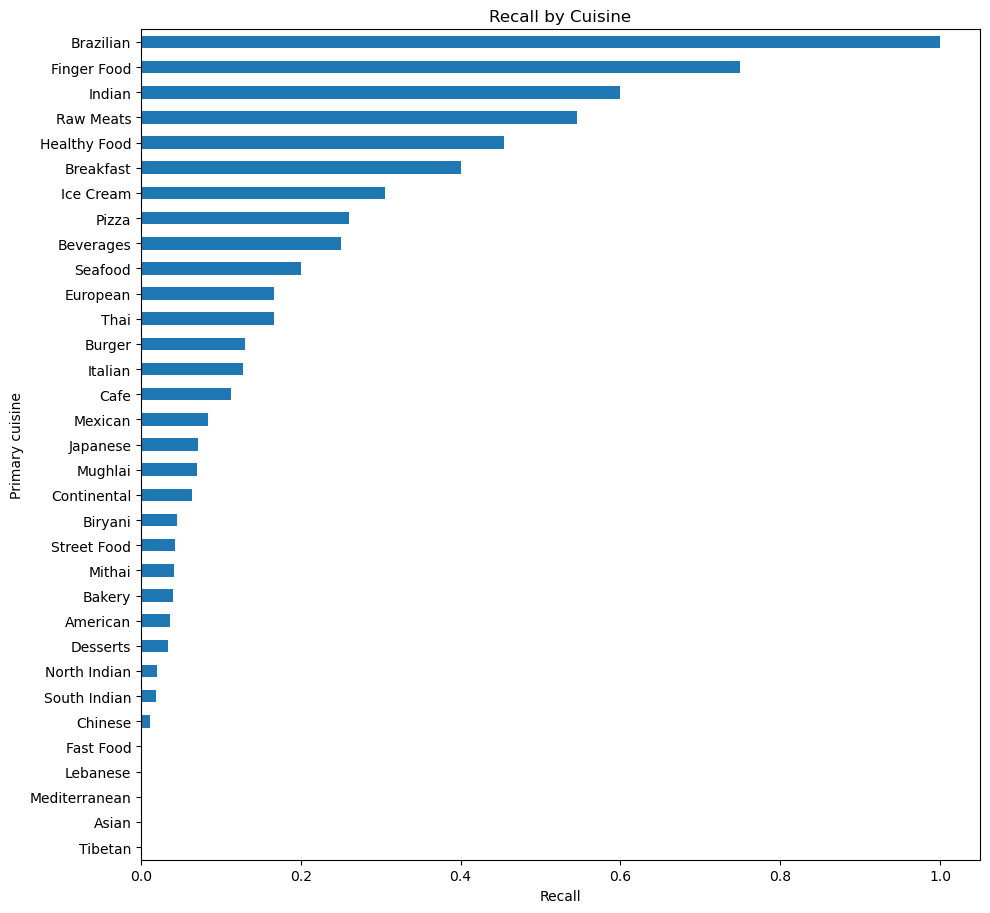

In [9]:
report = classification_report(
    y_test, y_pred, output_dict=True, zero_division=0
)

cuisine_report = pd.DataFrame(report).T
cuisine_report = cuisine_report.loc[
    cuisine_report.index.isin(y_model.unique().astype(str)),
    ["precision", "recall", "f1-score", "support"]
].sort_values("recall")

display(cuisine_report)

plt.figure(figsize=(10, max(5, len(cuisine_report) * 0.28)))
cuisine_report["recall"].plot(kind="barh")
plt.xlabel("Recall")
plt.ylabel("Primary cuisine")
plt.title("Recall by Cuisine")
plt.tight_layout()
plt.show()

10. Inspect Common Classification Errors

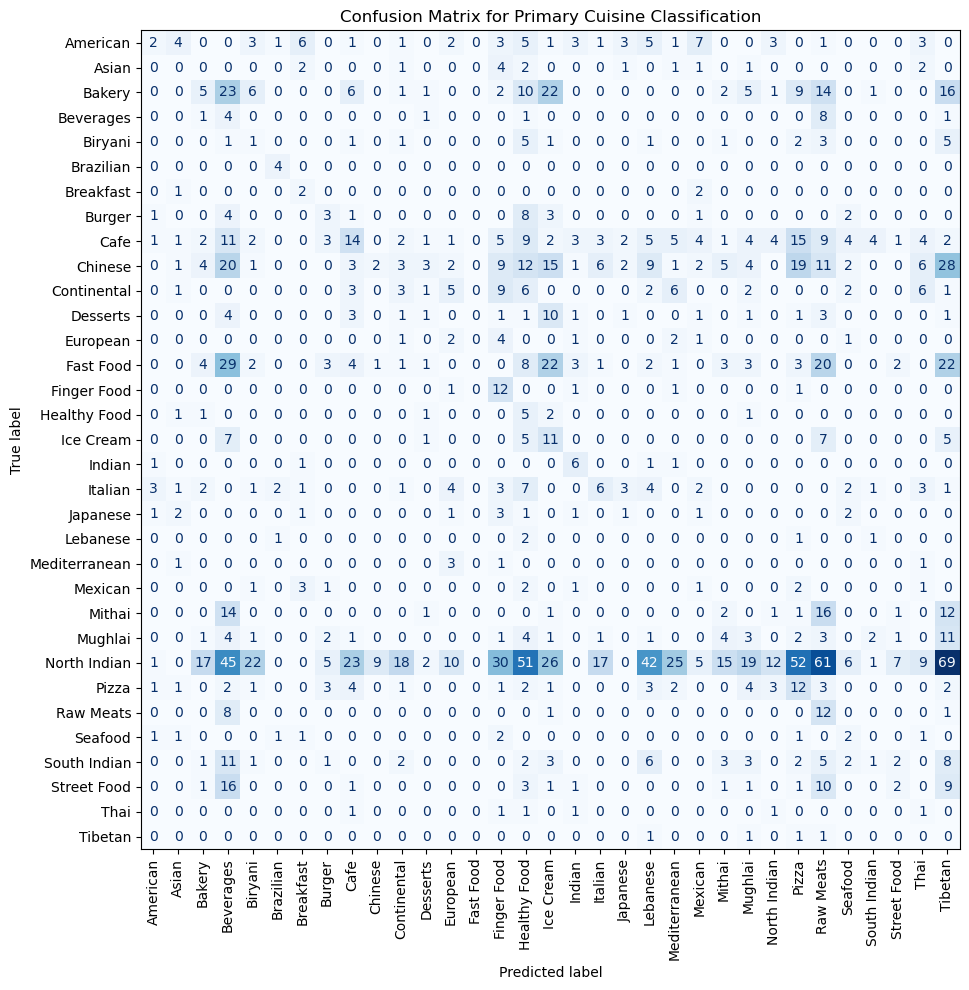

In [10]:
fig, ax = plt.subplots(figsize=(12, 10))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    xticks_rotation="vertical",
    cmap="Blues",
    ax=ax,
    colorbar=False
)
ax.set_title("Confusion Matrix for Primary Cuisine Classification")
plt.tight_layout()
plt.show()

##### 11. Challenges and Possible Biases

**1. Class Imbalance:** The dataset contains different numbers of restaurants for different cuisines. This can affect the model's ability to classify less-represented cuisines correctly.

**2. Rare Cuisines:** Cuisines with fewer than 20 records were excluded from training. Therefore, the model cannot predict these excluded cuisines.

**3. Similar Restaurant Features:** Restaurants serving different cuisines may have similar features, making it difficult for the model to distinguish between them.

**4. Low Model Performance:** The model achieved an accuracy of approximately 7.25%, with a macro precision of 10.65% and macro recall of 18.33%. These results indicate that the current model has difficulty classifying cuisines accurately.

**5. Potential Bias:** The model may perform differently across cuisines because some cuisines have more training examples than others. Its performance should therefore be evaluated separately for each cuisine.

**Possible Improvements:** Performance could be improved by trying other classification algorithms, selecting more informative features, tuning model parameters, and applying suitable techniques to address class imbalance.

### 12. Conclusion

In this task, a machine learning model was developed to classify restaurants based on their primary cuisine. The dataset was inspected and preprocessed by handling missing values, encoding categorical variables, and selecting suitable features. The data was divided into training and testing sets, and a Logistic Regression classifier was trained using a machine learning pipeline.

The model was evaluated using accuracy, macro precision, and macro recall. It achieved an accuracy of approximately 7.25%, indicating that its classification performance needs improvement. The analysis also highlighted challenges related to class imbalance, rare cuisines, and similarities between restaurant features.

In future work, different classification algorithms, improved feature engineering, and class-balancing techniques can be explored to improve prediction performance.